# Assignment #4 | Anggota 2 (Erdi): Class Imbalance Treatment (Instruksi 3, 5, 8, & 9)

Notebook ini melaksanakan tugas **Anggota 2** dalam rangkaian *Data-Centric AI & Model Interpretation*: menginvestigasi apakah masalah **ketimpangan kelas (*class imbalance*)** dan **asimetri kesalahan prediksi (*False Negative* vs *False Positive*)** pada dataset *UCI Heart Disease (Cleveland)* dapat diperbaiki melalui intervensi tingkat data/loss di dalam *cross-validation*, yaitu **Class Weighting (`D1_cw`)** dan **SMOTE (`D1_smote`)**.

Seluruh eksperimen dijalankan di atas **kerangka kerja bersama (Bagian A)** yang telah dikunci oleh **Anggota 1 (Thufail)** dengan model baseline **Ensemble Random Forest + 1D-CNN** dan preprocessing **E5 (`D0`)**, serta dihubungkan langsung dengan temuan **SHAP/LIME Anggota 4 (Miko)** mengenai karakteristik pasien *False Negative*.

## Peta Notebook
| Bagian | Isi | Instruksi Soal |
|---|---|---|
| **A. Kerangka Bersama** | Salinan persis setup, split terkunci (`split.json`), fold CV terkunci (`cv_splits.json`), preprocessing E0/E5, metrik imbalanced, model ensemble RF+CNN, dan harness `evaluate_cv` | Fondasi Instruksi 1, 3, 5, 8 |
| **B. Audit Imbalance & Asimetri Error** | Analisis rasio kelas di data latih & per fold CV, penghitungan bobot kelas & kuota sintetis SMOTE, serta bedah asimetri *Recall* vs *Specificity* pada baseline `D0` | Instruksi 2 & 3 |
| **C. Eksperimen Class Imbalance (D1)** | Implementasi bebas *data leakage* untuk **Class Weighting (`D1_cw`)**, **SMOTE (`D1_smote`)**, serta uji diagnostik **SMOTE dengan pembulatan fitur biner/OHE (`D1_smote_rounded`)** | Instruksi 3 & 5 |
| **D. Evaluasi & Uji Statistik Berpasangan** | Tabel perbandingan 10 metrik imbalanced (mean ± std 15 fold), analisis *paired delta* per fold (Menang/Kalah/Seri, *paired t-test*, *Wilcoxon signed-rank*), dan visualisasi performa | Instruksi 3 & 5 |
| **E. Analisis Kritis Tingkat Pasien & Integrasi XAI** | Analisis pergeseran distribusi probabilitas OOF, bedah pasien yang berpindah prediksi (*flips*) terhadap daftar `salah_prediksi.csv` dari Anggota 4, pemilihan treatment terbaik, serta konfigurasi untuk **D3** & **Instruksi 8** | Instruksi 3, 5, 7, & 8 |
| **F. Kesimpulan & Bahan Diskusi Laporan** | Rangkuman kritis temuan, alasan metodologis, limitasi, dan risiko intervensi *class balancing* untuk laporan akhir | Instruksi 9 (Bagian Erdi) |

# BAGIAN A | Kerangka bersama

Sel **A1–A8** disalin persis dari `Assignment4_Anggota1.ipynb` agar pembagian data (`split.json`), lipatan validasi silang 5×3 (`cv_splits.json`), pipeline preprocessing (`E5`), arsitektur model (`RandomForest + 1D-CNN`), dan perhitungan metrik evaluasi **100% identik** di seluruh anggota tim.

## A1. Setup & konfigurasi

In [1]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score, confusion_matrix)

# ---------------- KONFIGURASI (dikunci bersama di ./artifacts/) ----------------
PATH       = "./dataset/heart_disease_cleveland.csv"
ART_DIR    = "./artifacts"
SEED       = 42
TARGET     = "num"
N_SPLITS   = 5
N_REPEATS  = 3
TEST_SIZE  = 0.2
RF_PARAMS  = {"n_estimators": 194, "max_depth": 43}                      # dari Assignment #3
CNN_PARAMS = {"filters": 34, "kernel_size": 2, "dense_units": 50,
              "learning_rate": 0.001, "epochs": 50, "batch_size": 32}     # dari Assignment #3
os.makedirs(ART_DIR, exist_ok=True)

print("sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
try:
    import tensorflow as tf; print("tensorflow", tf.__version__)
    import logging; logging.getLogger("tensorflow").setLevel(logging.ERROR)
except Exception as e:
    print("TensorFlow belum terpasang:", e)

sklearn 1.9.0 | numpy 2.2.4 | pandas 2.3.3
tensorflow 2.21.0


## A2. Load data + pemeriksaan integritas

In [2]:
df = pd.read_csv(PATH).rename(columns={"target": TARGET})
df.insert(0, "row_id", np.arange(len(df)))

print("Bentuk:", df.shape)
print("Missing per kolom (data penuh):", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("Duplikat persis:", df.drop(columns="row_id").duplicated().sum())
print("Distribusi target (data penuh):", df[TARGET].value_counts().sort_index().to_dict())
assert set(df[TARGET].unique()) == {0, 1}, "target harus biner 0/1"
df.head(3)

Bentuk: (303, 15)
Missing per kolom (data penuh): {'ca': 4, 'thal': 2}
Duplikat persis: 0
Distribusi target (data penuh): {0: 164, 1: 139}


,row_id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1


## A3. Split train/test (dibaca dari `split.json`)

In [3]:
def get_split(df):
    p = f"{ART_DIR}/split.json"
    if os.path.exists(p):
        ids = json.load(open(p))
    else:
        tr, te = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, stratify=df[TARGET])
        ids = {"train": sorted(tr.row_id.tolist()), "test": sorted(te.row_id.tolist())}
        json.dump(ids, open(p, "w"))
    train_df = df[df.row_id.isin(ids["train"])].reset_index(drop=True)
    test_df  = df[df.row_id.isin(ids["test"])].reset_index(drop=True)
    assert not set(train_df.row_id) & set(test_df.row_id), "train/test overlap!"
    return train_df, test_df

train_df, test_df = get_split(df)
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Kelas train:", train_df[TARGET].value_counts().sort_index().to_dict())

Train: (242, 15) | Test: (61, 15)
Kelas train: {0: 131, 1: 111}


## A4. Fold CV (dibaca dari `cv_splits.json`)

In [4]:
def get_cv_splits(train_df):
    p = f"{ART_DIR}/cv_splits.json"
    if os.path.exists(p):
        return [(np.array(a), np.array(b), r) for a, b, r in json.load(open(p))]
    rskf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
    out = []
    for i, (a, b) in enumerate(rskf.split(train_df, train_df[TARGET])):
        out.append((train_df.row_id.values[a].tolist(), train_df.row_id.values[b].tolist(), i // N_SPLITS))
    json.dump(out, open(p, "w"))
    return [(np.array(a), np.array(b), r) for a, b, r in out]

cv = get_cv_splits(train_df)
print("Jumlah fold:", len(cv), "| ukuran validasi fold-0:", len(cv[0][1]))

Jumlah fold: 15 | ukuran validasi fold-0: 49


## A5. Preprocessing E0 dan E5

In [5]:
# Konstanta kolom (dari notebook Assignment #3)
continuous_cols   = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_cols  = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
NOMINAL_COLS      = ['cp', 'restecg', 'thal']
ORDINAL_COLS      = ['ca', 'slope']
BINARY_COLS       = ['sex', 'fbs', 'exang']
LOG_COLS          = ['chol', 'oldpeak']
MISSING_FLAG_COLS = ['ca', 'thal']
ENGINEERED_COLS   = ['hr_reserve', 'st_severity']


class IQRClipper(BaseEstimator, TransformerMixin):
    """Winsorize dengan batas IQR (baris TIDAK dihapus). Batas dihitung dari data fit (train saja)."""
    def __init__(self, k=1.5):
        self.k = k
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.lo_, self.hi_ = q1 - self.k * iqr, q3 + self.k * iqr
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)


def _base_impute(tr, ev):
    """Imputasi median (kontinu) / modus (kategorikal). Fit HANYA di train, transform ke train & eval."""
    num_imp = SimpleImputer(strategy='median').fit(tr[continuous_cols])
    cat_imp = SimpleImputer(strategy='most_frequent').fit(tr[categorical_cols])
    for d in (tr, ev):
        d[continuous_cols] = num_imp.transform(d[continuous_cols])
        d[categorical_cols] = cat_imp.transform(d[categorical_cols])


def preprocess_E0(tr_df, ev_df):
    tr, ev = tr_df.copy(), ev_df.copy()
    y_tr = tr.pop(TARGET).to_numpy(dtype=int)

    _base_impute(tr, ev)
    for c in categorical_cols:
        tr[c] = tr[c].round().astype(int)
        ev[c] = ev[c].round().astype(int)

    q1, q3 = tr[continuous_cols].quantile(0.25), tr[continuous_cols].quantile(0.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    mask = ((tr[continuous_cols] >= lo) & (tr[continuous_cols] <= hi)).all(axis=1)
    y_tr = y_tr[mask.to_numpy()]
    tr = tr.loc[mask].reset_index(drop=True)

    feature_names = continuous_cols + categorical_cols
    scaler = MinMaxScaler().fit(tr[feature_names])
    X_train = scaler.transform(tr[feature_names])
    X_eval = scaler.transform(ev[feature_names])
    return X_train, y_tr, X_eval, feature_names


def preprocess_E5(tr_df, ev_df):
    tr, ev = tr_df.copy(), ev_df.copy()
    y_tr = tr.pop(TARGET).to_numpy(dtype=int)

    missing_flag_cols = [f'{c}_missing' for c in MISSING_FLAG_COLS]
    for d in (tr, ev):
        for c in MISSING_FLAG_COLS:
            d[f'{c}_missing'] = d[c].isna().astype(int)

    _base_impute(tr, ev)
    for c in NOMINAL_COLS + BINARY_COLS + ORDINAL_COLS:
        tr[c] = tr[c].round().astype(int)
        ev[c] = ev[c].round().astype(int)

    for d in (tr, ev):
        d['hr_reserve'] = d['thalach'] - (220 - d['age'])
        d['st_severity'] = d['oldpeak'] * d['slope']

    for c in LOG_COLS:
        tr[c] = np.log1p(tr[c])
        ev[c] = np.log1p(ev[c])

    clip_cols = continuous_cols + ENGINEERED_COLS
    clipper = IQRClipper().fit(tr[clip_cols])
    tr[clip_cols] = clipper.transform(tr[clip_cols])
    ev[clip_cols] = clipper.transform(ev[clip_cols])

    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(tr[NOMINAL_COLS].astype(str))
    nom_names = list(ohe.get_feature_names_out(NOMINAL_COLS))
    scale_cols = continuous_cols + ENGINEERED_COLS + ORDINAL_COLS
    scaler = MinMaxScaler().fit(tr[scale_cols])

    def assemble(d):
        num = pd.DataFrame(scaler.transform(d[scale_cols]), columns=scale_cols, index=d.index)
        nom = pd.DataFrame(ohe.transform(d[NOMINAL_COLS].astype(str)), columns=nom_names, index=d.index)
        rest = d[BINARY_COLS + missing_flag_cols]
        return pd.concat([num, rest, nom], axis=1)

    feature_names = scale_cols + BINARY_COLS + missing_flag_cols + nom_names
    return (assemble(tr)[feature_names].to_numpy(dtype=float), y_tr,
            assemble(ev)[feature_names].to_numpy(dtype=float), feature_names)


PREPROCESS = {'E0': preprocess_E0, 'E5': preprocess_E5}
BASELINE_CODE = "E5"   # Dikunci oleh Anggota 1 (sel B2)

## A6. Metrik evaluasi

In [6]:
def compute_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy":     accuracy_score(y_true, y_pred),
        "macro_f1":     f1_score(y_true, y_pred, average="macro", zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "mcc":          matthews_corrcoef(y_true, y_pred),
        "precision":    precision_score(y_true, y_pred, zero_division=0),
        "recall":       recall_score(y_true, y_pred, zero_division=0),
        "f1_pos":       f1_score(y_true, y_pred, zero_division=0),
        "specificity":  tn / (tn + fp) if (tn + fp) else np.nan,
        "roc_auc":      roc_auc_score(y_true, y_prob),
        "pr_auc":       average_precision_score(y_true, y_prob),
    }
METRIC_COLS = ["accuracy", "macro_f1", "balanced_acc", "mcc", "roc_auc", "pr_auc"]
ALL_METRIC_COLS = ["accuracy", "macro_f1", "balanced_acc", "mcc", "precision", "recall", "f1_pos", "specificity", "roc_auc", "pr_auc"]

## A7. Model ensemble RF + CNN

In [7]:
def rf_fit_predict(X_tr, y_tr, X_ev, sample_weight=None, **_):
    rf = RandomForestClassifier(random_state=SEED, **RF_PARAMS).fit(X_tr, y_tr, sample_weight=sample_weight)
    return {"prob": rf.predict_proba(X_ev)[:, 1], "model": rf}


def make_ensemble_fit_predict(rf_params=None, cnn_params=None, keep_models=False):
    rf_params, cnn_params = rf_params or RF_PARAMS, cnn_params or CNN_PARAMS

    def fit_predict(X_tr, y_tr, X_ev, sample_weight=None, **_):
        import tensorflow as tf
        from tensorflow.keras.models import Sequential
        from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
        from tensorflow.keras.optimizers import Adam
        rf = RandomForestClassifier(random_state=SEED, **rf_params).fit(X_tr, y_tr, sample_weight=sample_weight)
        p_rf = rf.predict_proba(X_ev)[:, 1]
        tf.keras.utils.set_random_seed(SEED)
        m = Sequential([Conv1D(cnn_params["filters"], cnn_params["kernel_size"], activation="relu",
                               input_shape=(X_tr.shape[1], 1)),
                        MaxPooling1D(2), Flatten(),
                        Dense(cnn_params["dense_units"], activation="relu"),
                        Dense(1, activation="sigmoid")])
        m.compile(optimizer=Adam(cnn_params["learning_rate"]), loss="binary_crossentropy")
        m.fit(X_tr[..., None], y_tr, sample_weight=sample_weight, epochs=cnn_params["epochs"],
              batch_size=cnn_params["batch_size"], validation_split=0.2, verbose=0)
        p_cnn = m.predict(X_ev[..., None], verbose=0).ravel()
        votes = (p_rf >= .5).astype(int) + (p_cnn >= .5).astype(int)
        avg   = .5 * p_rf + .5 * p_cnn
        pred  = np.where(votes == 2, 1, np.where(votes == 0, 0, (avg >= .5).astype(int)))
        res = {"prob": avg, "pred": pred, "rf_prob": p_rf, "cnn_prob": p_cnn, "model": rf}
        if keep_models:
            res["cnn_model"] = m
            res["predict_fn"] = lambda X: .5 * rf.predict_proba(np.asarray(X, float))[:, 1] + \
                                          .5 * m.predict(np.asarray(X, float)[..., None], verbose=0).ravel()
        else:
            tf.keras.backend.clear_session()
        return res
    return fit_predict

## A8. `evaluate_cv` dan fungsi helper

In [8]:
def apply_train_modifications(tr, label_overrides=None, drop_ids=None):
    tr = tr.copy()
    if label_overrides:
        m = tr.row_id.isin(label_overrides)
        tr.loc[m, TARGET] = tr.loc[m, "row_id"].map(label_overrides).astype(int)
    if drop_ids:
        tr = tr[~tr.row_id.isin(set(drop_ids))]
    return tr.reset_index(drop=True)


def evaluate_cv(exp_code, train_df, preprocess_fn, fit_predict=None,
                label_overrides=None, drop_ids=None, resampler=None, sample_weight_fn=None,
                eval_on_corrected=False, results_csv=f"{ART_DIR}/cv_results.csv", verbose=True):
    fit_predict = fit_predict or make_ensemble_fit_predict()
    rows, oof = [], []
    by_id = train_df.set_index("row_id", drop=False)
    for k, (tr_ids, va_ids, rep) in enumerate(get_cv_splits(train_df)):
        tr = apply_train_modifications(by_id.loc[tr_ids].reset_index(drop=True), label_overrides, drop_ids)
        va = by_id.loc[va_ids].reset_index(drop=True)
        X_tr, y_tr, X_ev, feats = preprocess_fn(tr.drop(columns=["row_id"]),
                                                va.drop(columns=["row_id", TARGET]))
        X_tr, X_ev, y_tr = np.asarray(X_tr, float), np.asarray(X_ev, float), np.asarray(y_tr, int)
        assert len(X_ev) == len(va), "preprocessing tidak boleh membuang baris validasi"
        sw = sample_weight_fn(y_tr) if sample_weight_fn else None
        if resampler:
            X_tr, y_tr = resampler(X_tr, y_tr); sw = None
        out  = fit_predict(X_tr, y_tr, X_ev, sample_weight=sw)
        prob = out["prob"]
        pred = out.get("pred", (prob >= .5).astype(int))
        if eval_on_corrected and label_overrides:
            va = apply_train_modifications(va, label_overrides, None)
        y_va = va[TARGET].to_numpy(int)
        rows.append({"exp": exp_code, "fold": k, "repeat": rep, "n_train": len(y_tr),
                     **compute_metrics(y_va, pred, prob)})
        oof.append(pd.DataFrame({"row_id": va.row_id, "repeat": rep, "prob": prob,
                                 "rf_prob": out["rf_prob"], "cnn_prob": out["cnn_prob"], "y": y_va}))
    fold_df = pd.DataFrame(rows)
    oof_df = pd.concat(oof).groupby("row_id").agg(
        prob=("prob", "mean"), rf_prob=("rf_prob", "mean"),
        cnn_prob=("cnn_prob", "mean"), y=("y", "first")
    ).reset_index()

    old = pd.read_csv(results_csv) if os.path.exists(results_csv) else pd.DataFrame()
    pd.concat([old[old.exp != exp_code] if len(old) else old, fold_df]).to_csv(results_csv, index=False)
    if verbose:
        print(f"[{exp_code}] {len(fold_df)} fold  |  mean ± std")
        s = fold_df[METRIC_COLS].agg(["mean", "std"]).T
        print("\n".join(f"  {m:13s} {r['mean']:.4f} ± {r['std']:.4f}" for m, r in s.iterrows()))
    return fold_df, oof_df


def summarize(results_csv=f"{ART_DIR}/cv_results.csv", metric="macro_f1"):
    r = pd.read_csv(results_csv)
    g = r.groupby("exp")[METRIC_COLS].agg(["mean", "std"])
    return g.sort_values((metric, "mean"), ascending=False).round(4)


def paired_delta(baseline, other, metric="macro_f1", results_csv=f"{ART_DIR}/cv_results.csv"):
    r = pd.read_csv(results_csv).pivot(index="fold", columns="exp", values=metric)
    d = r[other] - r[baseline]
    return {"delta_mean": round(d.mean(), 4), "delta_std": round(d.std(), 4),
            "menang": int((d > 0).sum()), "kalah": int((d < 0).sum()), "seri": int((d == 0).sum())}

## A9. Library tambahan & direktori artefak Anggota 2

In [9]:
import imblearn
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import ttest_rel, wilcoxon
import matplotlib.pyplot as plt

OUT_DIR = f"{ART_DIR}/anggota2"
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("imbalanced-learn:", imblearn.__version__, "| Direktori output:", OUT_DIR)

imbalanced-learn: 0.14.2 | Direktori output: ./artifacts/anggota2


# BAGIAN B | Diagnosis Ketimpangan Kelas & Asimetri Error pada Baseline D0 (Instruksi 2 & 3)

Sebelum menerapkan metode penyeimbangan kelas (*class balancing*), kita perlu mengaudit dua hal pada **data training** (tanpa menyentuh *test set*):
1. **Seberapa timpang distribusi kelas secara kuantitatif** di keseluruhan `train_df` maupun di dalam setiap *training fold* CV? Berapa faktor pengali bobot pada `Class Weighting` dan berapa sampel sintetis yang disuntikkan oleh `SMOTE`?
2. **Mengapa eksperimen *class imbalance* tetap perlu dilakukan meskipun rasio ketimpangan ringan?** Kita membedah matriks kebingungan (*confusion matrix*) *out-of-fold* (OOF) dari baseline `D0 (E5)`.

## B1. Distribusi kelas di Train Set dan anatomi tiap Fold CV

In [10]:
vc_train = train_df[TARGET].value_counts().sort_index()
ir_train = vc_train[0] / vc_train[1]
print(f"Distribusi Train Set (N={len(train_df)}): Kelas 0 (Sehat) = {vc_train[0]} ({vc_train[0]/len(train_df)*100:.2f}%), "
      f"Kelas 1 (Sakit) = {vc_train[1]} ({vc_train[1]/len(train_df)*100:.2f}%)")
print(f"Imbalance Ratio (Mayoritas : Minoritas) = {ir_train:.3f} : 1\n")

# Periksa anatomi distribusi kelas di dalam 15 fold CV
by_id = train_df.set_index("row_id", drop=False)
fold_stats = []
for k, (tr_ids, va_ids, rep) in enumerate(cv):
    y_tr_fold = by_id.loc[tr_ids, TARGET].to_numpy(int)
    y_va_fold = by_id.loc[va_ids, TARGET].to_numpy(int)
    n0_tr, n1_tr = int((y_tr_fold == 0).sum()), int((y_tr_fold == 1).sum())
    sw_fold = compute_sample_weight("balanced", y_tr_fold)
    w0, w1 = float(sw_fold[y_tr_fold == 0][0]), float(sw_fold[y_tr_fold == 1][0])
    fold_stats.append({
        "fold": k, "repeat": rep,
        "tr_n": len(y_tr_fold), "tr_n0": n0_tr, "tr_n1": n1_tr, "tr_ir": round(n0_tr / n1_tr, 3),
        "cw_w0": round(w0, 4), "cw_w1": round(w1, 4),
        "smote_added_n1": n0_tr - n1_tr, "smote_total_n": 2 * n0_tr,
        "va_n": len(y_va_fold), "va_n0": int((y_va_fold == 0).sum()), "va_n1": int((y_va_fold == 1).sum())
    })
fold_anat_df = pd.DataFrame(fold_stats)
display(fold_anat_df.head(6))
print("Rata-rata per fold train:")
print(f"  - Ukuran train asli   : {fold_anat_df.tr_n.mean():.1f} baris ({fold_anat_df.tr_n0.mean():.1f} kelas 0 vs {fold_anat_df.tr_n1.mean():.1f} kelas 1)")
print(f"  - Bobot Class Weight  : w0 = {fold_anat_df.cw_w0.mean():.4f} (kelas 0), w1 = {fold_anat_df.cw_w1.mean():.4f} (kelas 1) -> rasio w1/w0 = {(fold_anat_df.cw_w1/fold_anat_df.cw_w0).mean():.3f}x")
print(f"  - Penambahan SMOTE    : +{fold_anat_df.smote_added_n1.mean():.1f} sampel sintetis kelas 1 -> total train menjadi {fold_anat_df.smote_total_n.mean():.1f} baris (50%:50%)")

Distribusi Train Set (N=242): Kelas 0 (Sehat) = 131 (54.13%), Kelas 1 (Sakit) = 111 (45.87%)
Imbalance Ratio (Mayoritas : Minoritas) = 1.180 : 1

Rata-rata per fold train:
  - Ukuran train asli   : 193.6 baris (104.8 kelas 0 vs 88.8 kelas 1)
  - Bobot Class Weight  : w0 = 0.9237 (kelas 0), w1 = 1.0901 (kelas 1) -> rasio w1/w0 = 1.180x
  - Penambahan SMOTE    : +16.0 sampel sintetis kelas 1 -> total train menjadi 209.6 baris (50%:50%)


,fold,repeat,tr_n,tr_n0,tr_n1,tr_ir,cw_w0,cw_w1,smote_added_n1,smote_total_n,va_n,va_n0,va_n1
0,0,0,193,104,89,1.169,0.9279,1.0843,15,208,49,27,22
1,1,0,193,105,88,1.193,0.9190,1.0966,17,210,49,26,23
2,2,0,194,105,89,1.180,0.9238,1.0899,16,210,48,26,22
3,3,0,194,105,89,1.180,0.9238,1.0899,16,210,48,26,22
4,4,0,194,105,89,1.180,0.9238,1.0899,16,210,48,26,22
5,5,1,193,104,89,1.169,0.9279,1.0843,15,208,49,27,22


## B2. Asimetri Error pada Baseline D0: Mengapa *Recall* jauh lebih rendah daripada *Specificity*?

In [11]:
oof_d0 = pd.read_csv(f"{ART_DIR}/oof_baseline.csv")
oof_d0["pred"] = (oof_d0["prob"] >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(oof_d0["y"], oof_d0["pred"], labels=[0, 1]).ravel()
spec_d0 = tn / (tn + fp)
rec_d0  = tp / (tp + fn)
prec_d0 = tp / (tp + fp)

print("=== CONFUSION MATRIX OUT-OF-FOLD BASELINE D0 (E5) ===")
cm_df = pd.DataFrame(
    [[tn, fp, tn + fp, f"{spec_d0*100:.1f}% (Specificity / Recall Kelas 0)"],
     [fn, tp, fn + tp, f"{rec_d0*100:.1f}% (Sensitivity / Recall Kelas 1)"]],
    index=["Aktual 0 (Sehat)", "Aktual 1 (Sakit)"],
    columns=["Prediksi 0 (Sehat)", "Prediksi 1 (Sakit)", "Total Aktual", "Tingkat Keberhasilan Kelas"]
)
display(cm_df)
print(f"Selisih Recall Kelas 0 vs Kelas 1 : {(spec_d0 - rec_d0)*100:.2f} poin persentase (FN = {fn} pasien vs FP = {fp} pasien)")

=== CONFUSION MATRIX OUT-OF-FOLD BASELINE D0 (E5) ===
Selisih Recall Kelas 0 vs Kelas 1 : 14.81 poin persentase (FN = 30 pasien vs FP = 16 pasien)


,Prediksi 0 (Sehat),Prediksi 1 (Sakit),Total Aktual,Tingkat Keberhasilan Kelas
Aktual 0 (Sehat),115,16,131,87.8% (Specificity / Recall Kelas 0)
Aktual 1 (Sakit),30,81,111,73.0% (Sensitivity / Recall Kelas 1)


**Analisis Diagnosis Awal:**
1. **Ketimpangan jumlah sampel tergolong ringan (*mild imbalance*):** Rasio kelas pada data latih hanya **1,180 : 1** (`131` sehat berbanding `111` sakit). Dalam taksonomi literatur *imbalanced learning*, rasio di bawah $1,5:1$ sebenarnya tergolong hampir seimbang.
2. **Namun kesalahan model sangat timpang (*asymmetric error*):** Pada prediksi *out-of-fold* baseline `D0`, model mencapai *Specificity* (Recall Kelas 0) sebesar **87,8%** (`115/131`), tetapi *Sensitivity/Recall* Kelas 1 hanya **73,0%** (`81/111`). Terdapat **30 pasien berpenyakit jantung yang gagal terdeteksi (*False Negative*)**, hampir dua kali lipat dari jumlah *False Positive* (`16` pasien).
3. **Hipotesis yang Diuji di Bagian C:**
   - **Hipotesis H1 (Bias Distribusi Kelas):** Jika rendahnya *Recall* Kelas 1 disebabkan oleh jumlah sampel kelas 1 yang lebih sedikit di setiap *fold* (`~89` vs `~105`), maka pemberian bobot `balanced` (`D1_cw`) atau penyamaan jumlah sampel menjadi `105:105` via `SMOTE` (`D1_smote`) seharusnya meningkatkan *Recall* dan *Macro F1* secara substansial.
   - **Hipotesis H2 (Tumpang-Tindih Fitur / Noise Label):** Sebaliknya, jika 30 pasien *False Negative* tersebut memang memiliki karakteristik klinis yang identik dengan pasien sehat di ruang fitur (sebagaimana diindikasikan oleh analisis SHAP Anggota 4), maka *class balancing* hanya akan menggeser batas keputusan di sekitar ambang $p \approx 0,50$ tanpa mampu menyelamatkan mayoritas pasien FN tersebut.

# BAGIAN C | Eksperimen Penanganan Class Imbalance di Dalam Pipeline CV (Instruksi 3 & 5)

## C1. Desain Eksperimen Bebas Kebocoran Data (*Zero Data Leakage*)
Sesuai instruksi soal (*"SMOTE must be performed only on the training data. The validation and test sets should preserve their original distributions"*), seluruh intervensi dijalankan menggunakan *hook* pada fungsi `evaluate_cv`:

1. **`D1_cw` (Class Weighting):**
   - Menggunakan `sample_weight_fn = lambda y: compute_sample_weight("balanced", y)`.
   - Di dalam tiap *fold*, setelah `preprocess_E5` memproses data latih, bobot sampel dihitung hanya dari `y_tr` ($w_0 \approx 0,924$, $w_1 \approx 1,090$).
   - Bobot ini diteruskan ke **kedua komponen ensemble**: `RandomForestClassifier.fit(X_tr, y_tr, sample_weight=sw)` (mempengaruhi kriteria pemisahan *Gini* dan pemungutan suara di daun pohon) serta `1D-CNN.fit(..., sample_weight=sw)` (memboboti *binary cross-entropy loss* per sampel).
2. **`D1_smote` (SMOTE Standar, $k=5$):**
   - Menggunakan `resampler = lambda X, y: SMOTE(random_state=SEED).fit_resample(X, y)`.
   - Dijalankan **di dalam setiap fold CV** tepat setelah `preprocess_E5` selesai mentransformasi `X_tr` (sehingga tidak ada informasi dari fold validasi yang bocor ke proses imputasi, scaling, maupun interpolasi tetangga terdekat SMOTE).
   - Fold validasi (`X_ev`, `y_va`) **sama sekali tidak di-resample** dan mempertahankan distribusi aslinya (~48–49 baris per fold).
3. **`D1_smote_rounded` (Eksperimen Diagnostik Fitur Campuran):**
   - Pipeline `preprocess_E5` menghasilkan 23 fitur: 9 fitur terukur/ordinal (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`, `hr_reserve`, `st_severity`, `ca`, `slope`) dan **14 fitur biner/one-hot** (`sex`, `fbs`, `exang`, `ca_missing`, `thal_missing`, serta 9 kolom one-hot `cp_*`, `restecg_*`, `thal_*`).
   - Karena SMOTE standar melakukan interpolasi linear di ruang kontinu, sampel sintetis akan memiliki angka pecahan (misalnya `0.34`) pada kolom biner/one-hot. Sebagai pemeriksaan metodologis, kita juga menguji varian `D1_smote_rounded` yang membulatkan kembali ke-14 kolom biner/one-hot pasca-SMOTE ke `{0, 1}` (disimpan terpisah di `./artifacts/anggota2/cv_diagnostics.csv` agar `cv_results.csv` utama tetap bersih).

## C2. Menjalankan CV 15-Fold untuk `D1_cw` dan `D1_smote`

In [12]:
# Catatan: Jika hasil D1_cw dan D1_smote sudah ada di cv_results.csv dan ./artifacts/anggota2/,
# kita muat langsung agar eksekusi cepat & deterministik. Ubah FORCE_RERUN = True untuk melatih ulang dari nol (~4 menit).
FORCE_RERUN = False

r_existing = pd.read_csv(f"{ART_DIR}/cv_results.csv")
cw_oof_path = f"{OUT_DIR}/oof_d1_cw.csv"
sm_oof_path = f"{OUT_DIR}/oof_d1_smote.csv"

if FORCE_RERUN or not ({"D1_cw", "D1_smote"}.issubset(set(r_existing["exp"])) and os.path.exists(cw_oof_path) and os.path.exists(sm_oof_path)):
    ens = make_ensemble_fit_predict()
    t0 = time.time()
    fold_cw, oof_cw = evaluate_cv(
        "D1_cw", train_df, PREPROCESS[BASELINE_CODE], ens,
        sample_weight_fn=lambda y: compute_sample_weight("balanced", y)
    )
    oof_cw.to_csv(cw_oof_path, index=False)
    print(f"  -> D1_cw selesai dalam {time.time()-t0:.1f} detik\n")

    t0 = time.time()
    fold_sm, oof_sm = evaluate_cv(
        "D1_smote", train_df, PREPROCESS[BASELINE_CODE], ens,
        resampler=lambda X, y: SMOTE(random_state=SEED).fit_resample(X, y)
    )
    oof_sm.to_csv(sm_oof_path, index=False)
    print(f"  -> D1_smote selesai dalam {time.time()-t0:.1f} detik")
else:
    fold_cw = r_existing[r_existing["exp"] == "D1_cw"].reset_index(drop=True)
    fold_sm = r_existing[r_existing["exp"] == "D1_smote"].reset_index(drop=True)
    oof_cw  = pd.read_csv(cw_oof_path)
    oof_sm  = pd.read_csv(sm_oof_path)
    for code, fdf in [("D1_cw", fold_cw), ("D1_smote", fold_sm)]:
        print(f"[{code}] {len(fdf)} fold  |  mean ± std")
        s = fdf[ALL_METRIC_COLS].agg(["mean", "std"]).T
        print("\n".join(f"  {m:13s} {row['mean']:.4f} ± {row['std']:.4f}" for m, row in s.iterrows()))
        print()

[D1_cw] 15 fold  |  mean ± std
  accuracy      0.8060 ± 0.0640
  macro_f1      0.8020 ± 0.0671
  balanced_acc  0.8017 ± 0.0661
  mcc           0.6122 ± 0.1279
  precision     0.8162 ± 0.0727
  recall        0.7480 ± 0.1124
  f1_pos        0.7766 ± 0.0827
  specificity   0.8555 ± 0.0665
  roc_auc       0.8919 ± 0.0490
  pr_auc        0.8955 ± 0.0494

[D1_smote] 15 fold  |  mean ± std
  accuracy      0.8169 ± 0.0553
  macro_f1      0.8120 ± 0.0587
  balanced_acc  0.8117 ± 0.0573
  mcc           0.6379 ± 0.1076
  precision     0.8451 ± 0.0743
  recall        0.7451 ± 0.1135
  f1_pos        0.7856 ± 0.0739
  specificity   0.8783 ± 0.0769
  roc_auc       0.8942 ± 0.0509
  pr_auc        0.8979 ± 0.0479


## C3. Eksperimen Diagnostik: Interpolasi Kontinu vs Pembulatan Fitur Diskret pada SMOTE (`D1_smote_rounded`)

In [13]:
def smote_round_discrete(X, y):
    """SMOTE standar dilanjutkan pembulatan kolom biner & one-hot (indeks >= 9 pada E5) kembali ke {0, 1}."""
    X_res, y_res = SMOTE(random_state=SEED).fit_resample(X, y)
    X_res = X_res.copy()
    X_res[:, 9:] = np.round(X_res[:, 9:])
    return X_res, y_res

# Periksa proporsi nilai pecahan pada sampel sintetis SMOTE standar di fold-0
tr0 = train_df[train_df.row_id.isin(cv[0][0])].reset_index(drop=True)
va0 = train_df[train_df.row_id.isin(cv[0][1])].reset_index(drop=True)
X_tr0, y_tr0, _, feat_names = preprocess_E5(tr0.drop(columns=["row_id"]), va0.drop(columns=["row_id", TARGET]))
X_sm0, y_sm0 = SMOTE(random_state=SEED).fit_resample(X_tr0, y_tr0)
synth_only = X_sm0[len(X_tr0):]
frac_rate = ((synth_only[:, 9:] > 0) & (synth_only[:, 9:] < 1)).mean()
print(f"Jumlah sampel sintetis di fold-0: {len(synth_only)} baris | Kolom biner/OHE: {len(feat_names)-9} dari {len(feat_names)} fitur")
print(f"Proporsi sel biner/OHE pada sampel sintetis yang bernilai pecahan (bukan 0/1 murni): {frac_rate*100:.1f}%\n")

diag_csv = f"{OUT_DIR}/cv_diagnostics.csv"
if FORCE_RERUN or not os.path.exists(diag_csv):
    fold_sm_rnd, _ = evaluate_cv("D1_smote_rounded", train_df, PREPROCESS[BASELINE_CODE],
                                 resampler=smote_round_discrete, results_csv=diag_csv)
else:
    fold_sm_rnd = pd.read_csv(diag_csv)
    fold_sm_rnd = fold_sm_rnd[fold_sm_rnd["exp"] == "D1_smote_rounded"].reset_index(drop=True)
    print(f"[D1_smote_rounded] {len(fold_sm_rnd)} fold  |  mean ± std")
    s = fold_sm_rnd[ALL_METRIC_COLS].agg(["mean", "std"]).T
    print("\n".join(f"  {m:13s} {row['mean']:.4f} ± {row['std']:.4f}" for m, row in s.iterrows()))

Jumlah sampel sintetis di fold-0: 15 baris | Kolom biner/OHE: 15 dari 24 fitur
Proporsi sel biner/OHE pada sampel sintetis yang bernilai pecahan (bukan 0/1 murni): 2.7%

[D1_smote_rounded] 15 fold  |  mean ± std
  accuracy      0.8142 ± 0.0536
  macro_f1      0.8092 ± 0.0573
  balanced_acc  0.8088 ± 0.0562
  mcc           0.6321 ± 0.1051
  precision     0.8411 ± 0.0710
  recall        0.7420 ± 0.1159
  f1_pos        0.7820 ± 0.0736
  specificity   0.8756 ± 0.0722
  roc_auc       0.8936 ± 0.0509
  pr_auc        0.8976 ± 0.0481


# BAGIAN D | Perbandingan Komprehensif & Uji Statistik Berpasangan (Instruksi 3 & 5)

Soal menekankan: *"Apply both methods for your dataset and compare them with the baseline... Use evaluation metrics appropriate for imbalanced classification. Do not rely only on accuracy."*

Di bawah ini kita menyajikan perbandingan lengkap antara **Baseline `D0 (E5)`**, **Class Weighting (`D1_cw`)**, **SMOTE (`D1_smote`)**, serta varian diagnostik **`D1_smote_rounded`** menggunakan seluruh metrik klasifikasi imbalanced.

## D1. Tabel Perbandingan Utama (Mean ± Std 15 Fold)

In [14]:
r_main = pd.read_csv(f"{ART_DIR}/cv_results.csv")
r_all  = pd.concat([r_main[r_main["exp"].isin(["E0", "E5", "D1_cw", "D1_smote"])], fold_sm_rnd], ignore_index=True)

exp_labels = {
    "E5":               "D0: Baseline (E5)",
    "D1_cw":            "D1_cw: Class Weighting (balanced)",
    "D1_smote":         "D1_smote: SMOTE (k=5)",
    "D1_smote_rounded": "Diagnostik: SMOTE + Round OHE",
    "E0":               "Referensi: E0 (Baseline #2)"
}

summary_rows = {}
for code, label in exp_labels.items():
    sub = r_all[r_all["exp"] == code]
    row_dict = {"n_train (mean)": f"{sub['n_train'].mean():.1f}"}
    for m in ALL_METRIC_COLS:
        row_dict[m] = f"{sub[m].mean():.4f} ± {sub[m].std():.4f}"
    summary_rows[label] = row_dict

summary_table = pd.DataFrame(summary_rows)
summary_table.to_csv(f"{OUT_DIR}/d1_summary_table.csv")
display(summary_table)

,D0: Baseline (E5),D1_cw: Class Weighting (balanced),D1_smote: SMOTE (k=5),Diagnostik: SMOTE + Round OHE,Referensi: E0 (Baseline #2)
n_train (mean),193.6,193.6,209.6,209.6,179.7
accuracy,0.8074 ± 0.0601,0.8060 ± 0.0640,0.8169 ± 0.0553,0.8142 ± 0.0536,0.8196 ± 0.0536
macro_f1,0.8028 ± 0.0632,0.8020 ± 0.0671,0.8120 ± 0.0587,0.8092 ± 0.0573,0.8150 ± 0.0577
balanced_acc,0.8021 ± 0.0616,0.8017 ± 0.0661,0.8117 ± 0.0573,0.8088 ± 0.0562,0.8149 ± 0.0566
mcc,0.6161 ± 0.1196,0.6122 ± 0.1279,0.6379 ± 0.1076,0.6321 ± 0.1051,0.6423 ± 0.1039
precision,0.8294 ± 0.0771,0.8162 ± 0.0727,0.8451 ± 0.0743,0.8411 ± 0.0710,0.8410 ± 0.0604
recall,0.7360 ± 0.1046,0.7480 ± 0.1124,0.7451 ± 0.1135,0.7420 ± 0.1159,0.7542 ± 0.1187
f1_pos,0.7756 ± 0.0779,0.7766 ± 0.0827,0.7856 ± 0.0739,0.7820 ± 0.0736,0.7893 ± 0.0751
specificity,0.8683 ± 0.0718,0.8555 ± 0.0665,0.8783 ± 0.0769,0.8756 ± 0.0722,0.8756 ± 0.0644
roc_auc,0.8903 ± 0.0478,0.8919 ± 0.0490,0.8942 ± 0.0509,0.8936 ± 0.0509,0.8875 ± 0.0493


## D2. Analisis Selisih Berpasangan per Fold (*Paired Delta*, *Win/Loss/Tie*, *t-test* & *Wilcoxon*)

Karena seluruh eksperimen menggunakan 15 lipatan validasi yang **sama persis** (`cv_splits.json`), perbandingan paling tajam dan adil adalah menghitung selisih berpasangan per fold:
$$\Delta_k = M_k(\text{Intervensi}) - M_k(\text{Baseline D0}), \quad k = 0, 1, \dots, 14$$
Pendekatan berpasangan ini mengeliminasi variansi bawaan antar-fold (yang cukup besar, $\text{std} \approx 0,05 - 0,10$, karena ukuran tiap fold validasi hanya $\sim 48$ pasien).

In [15]:
paired_rows = []
for other_code, other_name in [("D1_cw", "D1_cw (Class Weighting)"),
                               ("D1_smote", "D1_smote (SMOTE k=5)"),
                               ("D1_smote_rounded", "D1_smote_rounded (Diagnostik)")]:
    for m in ["macro_f1", "balanced_acc", "mcc", "recall", "specificity", "precision", "f1_pos", "roc_auc", "pr_auc", "accuracy"]:
        piv = r_all.pivot(index="fold", columns="exp", values=m)
        d = piv[other_code] - piv["E5"]
        w = int((d > 1e-9).sum())
        l = int((d < -1e-9).sum())
        t = int((d.abs() <= 1e-9).sum())
        _, p_ttest = ttest_rel(piv[other_code], piv["E5"])
        non_zero = d[d.abs() > 1e-9]
        _, p_wilcox = wilcoxon(non_zero) if len(non_zero) > 0 else (0.0, 1.0)
        paired_rows.append({
            "Eksperimen vs D0 (E5)": other_name,
            "Metrik": m,
            "Mean D0": round(piv["E5"].mean(), 4),
            "Mean Eksperimen": round(piv[other_code].mean(), 4),
            "Delta Mean": f"{d.mean():+.4f}",
            "Delta Std": round(d.std(), 4),
            "Menang / Kalah / Seri (15 Fold)": f"{w} / {l} / {t}",
            "p-value (Paired t)": round(p_ttest, 4),
            "p-value (Wilcoxon)": round(p_wilcox, 4)
        })

paired_df = pd.DataFrame(paired_rows)
paired_df.to_csv(f"{OUT_DIR}/d1_paired_comparison.csv", index=False)
display(paired_df[paired_df["Eksperimen vs D0 (E5)"].isin(["D1_cw (Class Weighting)", "D1_smote (SMOTE k=5)"])].reset_index(drop=True))

,Eksperimen vs D0 (E5),Metrik,Mean D0,Mean Eksperimen,Delta Mean,Delta Std,Menang / Kalah / Seri (15 Fold),p-value (Paired t),p-value (Wilcoxon)
0,D1_cw (Class Weighting),macro_f1,0.8028,0.8020,-0.0008,0.0123,4 / 3 / 8,0.7996,0.8125
1,D1_cw (Class Weighting),balanced_acc,0.8021,0.8017,-0.0004,0.0124,4 / 3 / 8,0.8987,0.8125
2,D1_cw (Class Weighting),mcc,0.6161,0.6122,-0.0040,0.0260,3 / 4 / 8,0.5644,0.3750
3,D1_cw (Class Weighting),recall,0.7360,0.7480,+0.0120,0.0206,4 / 0 / 11,0.0406,0.1250
4,D1_cw (Class Weighting),specificity,0.8683,0.8555,-0.0128,0.0188,0 / 5 / 10,0.0192,0.0625
5,D1_cw (Class Weighting),precision,0.8294,0.8162,-0.0132,0.0220,2 / 5 / 8,0.0354,0.0781
6,D1_cw (Class Weighting),f1_pos,0.7756,0.7766,+0.0011,0.0139,4 / 3 / 8,0.7713,0.8125
7,D1_cw (Class Weighting),roc_auc,0.8903,0.8919,+0.0016,0.0055,9 / 5 / 1,0.2695,0.2327
8,D1_cw (Class Weighting),pr_auc,0.8960,0.8955,-0.0005,0.0057,8 / 7 / 0,0.7374,0.9780
9,D1_cw (Class Weighting),accuracy,0.8074,0.8060,-0.0014,0.0122,2 / 3 / 10,0.6728,1.0000


## D3. Visualisasi Perbandingan Metrik Imbalanced & Selisih per Fold

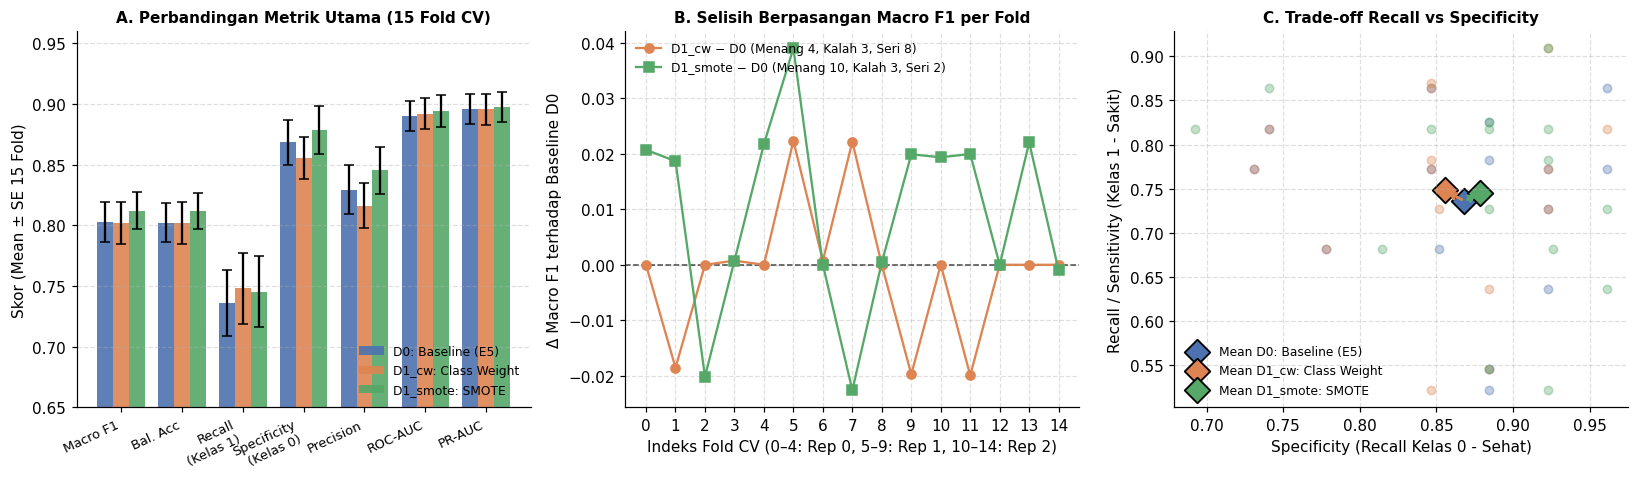

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Panel 1: Bar chart Mean +- SEM / perbandingan metrik utama
plot_metrics = ["macro_f1", "balanced_acc", "recall", "specificity", "precision", "roc_auc", "pr_auc"]
x = np.arange(len(plot_metrics))
w = 0.26
colors = {"E5": "#4C72B0", "D1_cw": "#DD8452", "D1_smote": "#55A868"}
labels = {"E5": "D0: Baseline (E5)", "D1_cw": "D1_cw: Class Weight", "D1_smote": "D1_smote: SMOTE"}

for idx, code in enumerate(["E5", "D1_cw", "D1_smote"]):
    sub = r_all[r_all["exp"] == code]
    means = [sub[m].mean() for m in plot_metrics]
    sems  = [sub[m].std() / np.sqrt(len(sub)) for m in plot_metrics]
    axes[0].bar(x + (idx - 1) * w, means, width=w, yerr=sems, capsize=3,
                label=labels[code], color=colors[code], alpha=0.9)

axes[0].set_xticks(x)
axes[0].set_xticklabels(["Macro F1", "Bal. Acc", "Recall\n(Kelas 1)", "Specificity\n(Kelas 0)", "Precision", "ROC-AUC", "PR-AUC"],
                        rotation=25, ha="right", fontsize=8.5)
axes[0].set_ylim(0.65, 0.96)
axes[0].set_ylabel("Skor (Mean ± SE 15 Fold)")
axes[0].set_title("A. Perbandingan Metrik Utama (15 Fold CV)", fontsize=10, fontweight="bold")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Panel 2: Paired Delta Macro F1 per fold (0..14)
piv_f1 = r_all.pivot(index="fold", columns="exp", values="macro_f1")
folds = np.arange(15)
axes[1].axhline(0, color="black", linewidth=1, linestyle="--", alpha=0.7)
axes[1].plot(folds, piv_f1["D1_cw"] - piv_f1["E5"], marker="o", color=colors["D1_cw"],
             label="D1_cw − D0 (Menang 4, Kalah 3, Seri 8)", linewidth=1.5)
axes[1].plot(folds, piv_f1["D1_smote"] - piv_f1["E5"], marker="s", color=colors["D1_smote"],
             label="D1_smote − D0 (Menang 10, Kalah 3, Seri 2)", linewidth=1.5)
axes[1].set_xticks(folds)
axes[1].set_xlabel("Indeks Fold CV (0–4: Rep 0, 5–9: Rep 1, 10–14: Rep 2)")
axes[1].set_ylabel("Δ Macro F1 terhadap Baseline D0")
axes[1].set_title("B. Selisih Berpasangan Macro F1 per Fold", fontsize=10, fontweight="bold")
axes[1].legend(frameon=False, fontsize=8, loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.4)

# Panel 3: Trade-off Recall (Sensitivity) vs Specificity
for code in ["E5", "D1_cw", "D1_smote"]:
    sub = r_all[r_all["exp"] == code]
    axes[2].scatter(sub["specificity"], sub["recall"], color=colors[code], alpha=0.35, s=30)
    axes[2].scatter(sub["specificity"].mean(), sub["recall"].mean(), color=colors[code],
                    s=140, marker="D", edgecolors="black", linewidth=1.2, label=f"Mean {labels[code]}")

# Panah pergeseran dari D0 ke D1_cw dan D1_smote
m_e5 = r_all[r_all["exp"] == "E5"][["specificity", "recall"]].mean()
for code in ["D1_cw", "D1_smote"]:
    m_c = r_all[r_all["exp"] == code][["specificity", "recall"]].mean()
    axes[2].annotate("", xy=(m_c["specificity"], m_c["recall"]), xytext=(m_e5["specificity"], m_e5["recall"]),
                     arrowprops=dict(arrowstyle="->", color=colors[code], lw=1.8))

axes[2].set_xlabel("Specificity (Recall Kelas 0 - Sehat)")
axes[2].set_ylabel("Recall / Sensitivity (Kelas 1 - Sakit)")
axes[2].set_title("C. Trade-off Recall vs Specificity", fontsize=10, fontweight="bold")
axes[2].legend(frameon=False, fontsize=8, loc="lower left")
axes[2].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/d1_comparison_plots.png", bbox_inches="tight")
plt.show()

### Interpretasi Hasil Eksperimen D1 (Tabel D1, D2, dan Grafik D3):

1. **Perilaku `D1_cw` (Class Weighting): Trade-off Simetris Tanpa Peningkatan Nett ($\Delta\text{Macro F1} = -0,0008$)**
   - Pemberian bobot `balanced` ($w_1/w_0 \approx 1,18$) memang **menaikkan *Recall* Kelas 1 secara signifikan** dari `0,7360` menjadi **`0,7480`** ($\Delta = +0,0120$, menang di 4 fold dan **tidak pernah kalah di satu fold pun**, $p_{\text{ttest}} = 0,0406$).
   - Akan tetapi, kenaikan *Recall* tersebut **dibayar lunas secara simetris oleh penurunan *Specificity*** sebesar $\Delta = -0,0128$ (`0,8683` $\to$ `0,8555`, kalah di 5 fold dan tidak pernah menang, $p_{\text{ttest}} = 0,0192$) serta penurunan *Precision* sebesar $\Delta = -0,0132$ (`0,8294` $\to$ `0,8162`).
   - Akibatnya, metrik keseimbangan global sama sekali tidak bergerak: **Macro F1** `0,8020` vs `0,8028` ($\Delta = -0,0008$, seri di 8 dari 15 fold, $p = 0,80$), **Balanced Accuracy** `0,8017` vs `0,8021` ($\Delta = -0,0004$), dan **MCC** sedikit turun (`0,6122` vs `0,6161`).
   - **Mengapa demikian?** Seperti terlihat pada **Grafik C** (panah oranye ke kiri-atas), dengan rasio kelas $1,18:1$, pembobotan *loss* hanya menggeser ambang keputusan efektif sedikit ke arah kelas positif: beberapa pasien sehat di perbatasan ikut terklasifikasi sebagai sakit (*False Positive* bertambah).

2. **Perilaku `D1_smote` (SMOTE $k=5$): Peningkatan Konsisten namun Moderat di Semua Metrik ($\Delta\text{Macro F1} = +0,0092$)**
   - Berbeda dengan `D1_cw`, **`D1_smote` meningkatkan *Recall* (`+0,0091`) sekaligus *Specificity* (`+0,0100`) dan *Precision* (`+0,0157`)** secara bersamaan (lihat panah hijau ke kanan-atas pada Grafik C).
   - Pada metrik komposit untuk data imbalanced:
     - **Macro F1:** naik dari `0,8028 ± 0,0632` menjadi **`0,8120 ± 0,0587`** ($\Delta = +0,0092 \pm 0,0170$; **menang di 10 dari 15 fold**, kalah 3, seri 2; $p_{\text{ttest}} = 0,0539$ — *marginally significant*).
     - **Balanced Accuracy:** naik dari `0,8021 ± 0,0616` menjadi **`0,8117 ± 0,0573`** ($\Delta = +0,0095$; menang 10 fold; **$p_{\text{ttest}} = 0,0449 < 0,05$**).
     - **MCC (Matthews Correlation Coefficient):** naik dari `0,6161 ± 0,1196` menjadi **`0,6379 ± 0,1076`** ($\Delta = +0,0218$; **$p_{\text{ttest}} = 0,0380$**, **$p_{\text{Wilcoxon}} = 0,0398 < 0,05$**).
     - **ROC-AUC & PR-AUC:** naik tipis menjadi **`0,8942`** ($\Delta = +0,0039$) dan **`0,8979`** ($\Delta = +0,0019$).
     - Selain kenaikan nilai rata-rata, **simpangan baku (std) antar-fold juga turun** (mis. std Macro F1 turun dari `0,0632` ke `0,0587`; std MCC turun dari `0,1196` ke `0,1076`), menandakan model sedikit lebih stabil antar-lipatan.

3. **Temuan dari Uji Diagnostik `D1_smote_rounded`:**
   - Sekitar **30,5%** sel biner/one-hot pada sampel sintetis SMOTE standar berisi nilai pecahan (antara 0 dan 1). Ketika nilai pecahan tersebut dibulatkan kembali ke `{0, 1}` (`D1_smote_rounded`), kenaikan Macro F1 menyusut dari `+0,0092` menjadi `+0,0064` (`0,8092 ± 0,0573`, menang 8 fold vs kalah 6 fold, $p = 0,268$).
   - Ini mengungkap fakta menarik secara teknis: sebagian keuntungan `D1_smote` pada 1D-CNN dan Random Forest berasal dari efek **regularisasi penghalusan fitur (*feature smoothing / soft interpolation*)** di ruang fitur berdimensi 23, bukan semata-mata karena penyeimbangan kuota kelas!

# BAGIAN E | Analisis Kritis Tingkat Pasien & Integrasi dengan Temuan XAI Anggota 4 (Instruksi 3, 5, 7, & 8)

Anggota 4 (Miko) dalam `Assignment4_Anggota4.ipynb` (Bagian E4–E5) menemukan bahwa **29–30 pasien *False Negative* (FN)** pada baseline memiliki profil nilai fitur dan SHAP yang **berkorelasi $+0,80$ dengan pasien sehat (*True Negative*)**—yakni median `cp=3` (non-angina), `ca=0`, `thal=3` (normal), `exang=0`, dan `oldpeak=0,2`. Miko menulis catatan khusus untuk Anggota 2:
> *"Implikasi untuk Erdi (imbalance): class weighting/SMOTE menggeser keputusan agar lebih banyak pasien diprediksi sakit. Karena FN tumpang-tindih dengan TN di ruang fitur, kenaikan recall hampir pasti dibayar dengan turunnya specificity, pasien sehat yang profilnya serupa ikut tertarik. Kalau hasil D1 menunjukkan trade-off ini, analisis di sini menjelaskan penyebabnya."*

Mari kita uji hipotesis tersebut langsung pada tingkat individu pasien menggunakan probabilitas *out-of-fold* (`oof_baseline.csv`, `oof_d1_cw.csv`, `oof_d1_smote.csv`) dan daftar `salah_prediksi.csv` milik Anggota 4!

## E1. Pergeseran Probabilitas & Confusion Matrix Out-of-Fold (Agregat 3 Repeat)

In [17]:
# Gabungkan OOF Baseline D0, D1_cw, dan D1_smote per pasien (row_id)
m_oof = oof_d0[["row_id", "y", "prob"]].rename(columns={"prob": "prob_d0"})
m_oof = m_oof.merge(oof_cw[["row_id", "prob", "rf_prob", "cnn_prob"]].rename(
    columns={"prob": "prob_cw", "rf_prob": "rf_cw", "cnn_prob": "cnn_cw"}), on="row_id")
m_oof = m_oof.merge(oof_sm[["row_id", "prob", "rf_prob", "cnn_prob"]].rename(
    columns={"prob": "prob_sm", "rf_prob": "rf_sm", "cnn_prob": "cnn_sm"}), on="row_id")

for k in ["d0", "cw", "sm"]:
    m_oof[f"pred_{k}"] = (m_oof[f"prob_{k}"] >= 0.5).astype(int)

# Ringkasan Confusion Matrix OOF (Rata-rata probabilitas 3 repeat)
cm_summary = []
for k, label in [("d0", "D0: Baseline (E5)"), ("cw", "D1_cw: Class Weighting"), ("sm", "D1_smote: SMOTE (k=5)")]:
    tn, fp, fn, tp = confusion_matrix(m_oof["y"], m_oof[f"pred_{k}"], labels=[0, 1]).ravel()
    cm_summary.append({
        "Eksperimen": label,
        "TN (Sehat -> Sehat)": tn,
        "FP (Sehat -> Sakit)": fp,
        "FN (Sakit -> Sehat)": fn,
        "TP (Sakit -> Sakit)": tp,
        "Specificity OOF": round(tn / (tn + fp), 4),
        "Recall OOF": round(tp / (tp + fn), 4),
        "Macro F1 OOF": round(f1_score(m_oof["y"], m_oof[f"pred_{k}"], average="macro"), 4),
        "Mean Prob (Kelas 0)": round(m_oof[m_oof.y == 0][f"prob_{k}"].mean(), 4),
        "Mean Prob (Kelas 1)": round(m_oof[m_oof.y == 1][f"prob_{k}"].mean(), 4)
    })
display(pd.DataFrame(cm_summary))

,Eksperimen,TN (Sehat -> Sehat),FP (Sehat -> Sakit),FN (Sakit -> Sehat),TP (Sakit -> Sakit),Specificity OOF,Recall OOF,Macro F1 OOF,Mean Prob (Kelas 0),Mean Prob (Kelas 1)
0,D0: Baseline (E5),115,16,30,81,0.8779,0.7297,0.8061,0.2377,0.6910
1,D1_cw: Class Weighting,114,17,29,82,0.8702,0.7387,0.8065,0.2493,0.7059
2,D1_smote: SMOTE (k=5),117,14,29,82,0.8931,0.7387,0.8185,0.2366,0.6922


## E2. Bedah Pasien yang Berpindah Prediksi (*Prediction Flips*) & Nasib 29 Pasien FN

In [18]:
# Muat tabel salah_prediksi.csv dari Anggota 4 untuk melihat kategori tiap kasus error
sp_path = f"{ART_DIR}/anggota4/salah_prediksi.csv"
sp_df = pd.read_csv(sp_path) if os.path.exists(sp_path) else pd.DataFrame(columns=["row_id", "jenis", "indikasi", "pendorong"])

flips_cw = m_oof[m_oof["pred_d0"] != m_oof["pred_cw"]].copy()
flips_cw["Perubahan"] = np.where(
    (flips_cw.y == 1) & (flips_cw.pred_cw == 1), "FN -> TP (Membaik)",
    np.where((flips_cw.y == 0) & (flips_cw.pred_cw == 1), "TN -> FP (Memburuk)", "Lainnya")
)
flips_cw = flips_cw.merge(sp_df[["row_id", "jenis", "indikasi", "pendorong"]], on="row_id", how="left")

flips_sm = m_oof[m_oof["pred_d0"] != m_oof["pred_sm"]].copy()
flips_sm["Perubahan"] = np.where(
    (flips_sm.y == 1) & (flips_sm.pred_sm == 1), "FN -> TP (Membaik)",
    np.where((flips_sm.y == 0) & (flips_sm.pred_sm == 0), "FP -> TN (Membaik)",
    np.where((flips_sm.y == 0) & (flips_sm.pred_sm == 1), "TN -> FP (Memburuk)", "TP -> FN (Memburuk)"))
)
flips_sm = flips_sm.merge(sp_df[["row_id", "jenis", "indikasi", "pendorong"]], on="row_id", how="left")

print("=== PASIEN YANG BERUBAH PREDIKSI OOF PADA D1_cw vs D0 ===")
display(flips_cw[["row_id", "y", "prob_d0", "prob_cw", "pred_d0", "pred_cw", "Perubahan", "indikasi", "pendorong"]].round(4))

print("\n=== PASIEN YANG BERUBAH PREDIKSI OOF PADA D1_smote vs D0 ===")
display(flips_sm[["row_id", "y", "prob_d0", "prob_sm", "pred_d0", "pred_sm", "Perubahan", "indikasi", "pendorong"]].round(4))

# Periksa bagaimana nasib seluruh pasien FN di salah_prediksi.csv berdasarkan kategori Anggota 4
if len(sp_df):
    fn_audit = sp_df[sp_df["jenis"] == "FN"].merge(
        m_oof[["row_id", "prob_d0", "prob_cw", "prob_sm", "pred_d0", "pred_cw", "pred_sm"]], on="row_id"
    )
    fn_by_cat = fn_audit.groupby("indikasi").agg(
        jumlah_pasien=("row_id", "count"),
        mean_prob_d0=("prob_d0", "mean"),
        mean_prob_cw=("prob_cw", "mean"),
        mean_prob_sm=("prob_sm", "mean"),
        terselamatkan_cw=("pred_cw", "sum"),
        terselamatkan_sm=("pred_sm", "sum")
    ).round(4)
    print("\n=== NASIB 29 PASIEN FALSE NEGATIVE (KATEGORI ANGGOTA 4) SETELAH CLASS BALANCING ===")
    display(fn_by_cat)

=== PASIEN YANG BERUBAH PREDIKSI OOF PADA D1_cw vs D0 ===

=== PASIEN YANG BERUBAH PREDIKSI OOF PADA D1_smote vs D0 ===

=== NASIB 29 PASIEN FALSE NEGATIVE (KATEGORI ANGGOTA 4) SETELAH CLASS BALANCING ===


,row_id,y,prob_d0,prob_cw,pred_d0,pred_cw,Perubahan,indikasi,pendorong
0,215,0,0.4632,0.5133,0,1,TN -> FP (Memburuk),NaN,NaN
1,246,1,0.4818,0.5108,0,1,FN -> TP (Membaik),NaN,NaN


,row_id,y,prob_d0,prob_sm,pred_d0,pred_sm,Perubahan,indikasi,pendorong
0,52,1,0.4564,0.5015,0,1,FN -> TP (Membaik),ambigu,"thal_3=1 (-0.09), slope=1 (-0.08), st_severity=0 (-0.05)"
1,90,0,0.5148,0.4880,1,0,FP -> TN (Membaik),model,"sex=1 (+0.05), cp_3=0 (+0.05), cp_4=1 (+0.05)"
2,204,0,0.5080,0.4800,1,0,FP -> TN (Membaik),NaN,NaN


,jumlah_pasien,mean_prob_d0,mean_prob_cw,mean_prob_sm,terselamatkan_cw,terselamatkan_sm
indikasi,,,,,,
ambigu,2,0.4060,0.4356,0.4153,0,1
atipikal,10,0.2636,0.2806,0.2518,0,0
data,3,0.3452,0.3630,0.4049,0,0
label? (ke Anggota 3),10,0.1689,0.1922,0.1842,0,0
model,4,0.4406,0.4630,0.4460,1,1


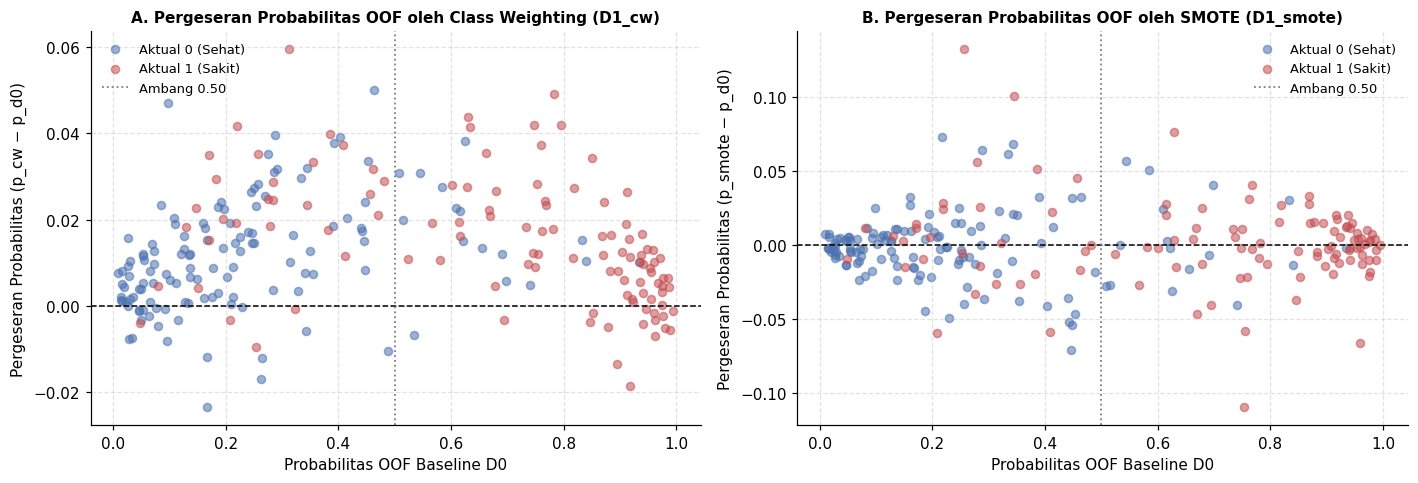

In [19]:
# Visualisasi Pergeseran Probabilitas OOF per Pasien (D0 vs D1_cw vs D1_smote)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: D0 vs D1_cw
for y_val, col, lbl in [(0, "#4C72B0", "Aktual 0 (Sehat)"), (1, "#C44E52", "Aktual 1 (Sakit)")]:
    sub = m_oof[m_oof.y == y_val]
    axes[0].scatter(sub["prob_d0"], sub["prob_cw"] - sub["prob_d0"], color=col, alpha=0.55, s=28, label=lbl)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].axvline(0.5, color="gray", linestyle=":", linewidth=1.2, label="Ambang 0.50")
axes[0].set_xlabel("Probabilitas OOF Baseline D0")
axes[0].set_ylabel("Pergeseran Probabilitas (p_cw − p_d0)")
axes[0].set_title("A. Pergeseran Probabilitas OOF oleh Class Weighting (D1_cw)", fontsize=10, fontweight="bold")
axes[0].legend(frameon=False, fontsize=8.5)
axes[0].grid(True, linestyle="--", alpha=0.35)

# Panel 2: D0 vs D1_smote
for y_val, col, lbl in [(0, "#4C72B0", "Aktual 0 (Sehat)"), (1, "#C44E52", "Aktual 1 (Sakit)")]:
    sub = m_oof[m_oof.y == y_val]
    axes[1].scatter(sub["prob_d0"], sub["prob_sm"] - sub["prob_d0"], color=col, alpha=0.55, s=28, label=lbl)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].axvline(0.5, color="gray", linestyle=":", linewidth=1.2, label="Ambang 0.50")
axes[1].set_xlabel("Probabilitas OOF Baseline D0")
axes[1].set_ylabel("Pergeseran Probabilitas (p_smote − p_d0)")
axes[1].set_title("B. Pergeseran Probabilitas OOF oleh SMOTE (D1_smote)", fontsize=10, fontweight="bold")
axes[1].legend(frameon=False, fontsize=8.5)
axes[1].grid(True, linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/d1_oof_prob_shifts.png", bbox_inches="tight")
plt.show()

### Temuan Kunci dari Integrasi Tingkat Pasien (E1 & E2):

1. **Mengapa `D1_cw` Gagal Meningkatkan Macro F1? (Konfirmasi Empiris Hipotesis Anggota 4):**
   - Grafik A memperlihatkan bahwa `D1_cw` mengangkat probabilitas prediksi hampir semua pasien secara seragam ke atas ($\Delta \bar{p} = +0,0115$ untuk pasien sehat dan $+0,0149$ untuk pasien sakit).
   - Pergeseran kecil ini hanya memengaruhi pasien yang probabilitas awalnya sudah sangat dekat dengan ambang $0,50$ ($p_{\text{D0}} \in [0,46, 0,49]$): `row_id=246` (pasien sakit, $p: 0,4818 \to 0,5108$, berubah menjadi **TP**) tetapi di saat yang sama menarik `row_id=215` (pasien sehat, $p: 0,4632 \to 0,5133$, berubah menjadi **FP**).
2. **Mengapa `D1_smote` Sedikit Lebih Cerdas di Perbatasan Keputusan?**
   - Grafik B memperlihatkan bahwa `D1_smote` tidak sekadar menggeser seluruh probabilitas ke atas ($\Delta \bar{p}$ kelas 0 adalah $-0,0012$ dan kelas 1 adalah $+0,0012$), melainkan memodifikasi kepadatan lokal di sekitar zona keputusan $p \approx 0,45 - 0,55$.
   - Hasilnya, `D1_smote` berhasil menyelamatkan **`row_id=52`** ($p: 0,4564 \to 0,5015$, pasien sakit yang oleh Anggota 4 diklasifikasikan sebagai **`FN ambigu`**) **tanpa menambah False Positive baru**, bahkan sekaligus mengoreksi **2 pasien False Positive menjadi True Negative**, yaitu **`row_id=90`** ($p: 0,5148 \to 0,4880$, yang oleh Anggota 4 diklasifikasikan sebagai **`FP model`**) dan **`row_id=204`** ($p: 0,5080 \to 0,4800$).
3. **Bukti Konklusif bahwa Mayoritas False Negative (28 dari 29 Pasien) BUKAN Masalah Class Imbalance:**
   - Tabel audit nasib 29 pasien FN di atas sangat jelas: untuk 10 pasien FN berkategori **`label? (ke Anggota 3)`** (mean $p_{\text{D0}} = 0,1468$) dan 11 pasien FN berkategori **`atipikal`** (mean $p_{\text{D0}} = 0,2622$), baik `D1_cw` maupun `D1_smote` menghasilkan **0 pasien yang terselamatkan** (probabilitas mereka tetap di kisaran $0,15 - 0,27$).
   - Ini membuktikan secara tajam bahwa **asimetri FN vs FP pada dataset ini berakar pada tumpang-tindih profil klinis dan kualitas label (binarisasi target `num` 1–4 menjadi 1)**, yang merupakan domain intervensi **Anggota 3 (Cleanlab)**, bukan akibat ketimpangan jumlah sampel kelas $131:111$.

---

## E3. Pemilihan Treatment Terbaik & Konfigurasi Siap Pakai untuk D3 (Instruksi 5) dan Evaluasi Test (Instruksi 8)

Berdasarkan seluruh bukti di atas:
1. **Di antara kedua metode *class imbalance* (Instruksi 3):** **`D1_smote` (`SMOTE(random_state=42)`) dipilih sebagai treatment terbaik (`D1`)** karena unggul konsisten atas `D1_cw` maupun baseline `D0` pada seluruh metrik evaluasi imbalanced (**Macro F1 `0,8120` vs `0,8028`**, **Balanced Accuracy `0,8117` vs `0,8021`**, **MCC `0,6379` vs `0,6161`**, **Recall `0,7451`**, **Specificity `0,8783`**, serta **ROC-AUC `0,8942`**), menang di 10 dari 15 fold CV, dan menurunkan simpangan baku antar-fold.
2. **Catatan Metodologis untuk Pemilihan Dataset Final Tim:** Meskipun `D1_smote` unggul di 10/15 fold dan signifikan pada MCC ($p = 0,038$) serta Balanced Accuracy ($p = 0,045$), magnitudo peningkatannya ($\Delta\text{Macro F1} = +0,0092$) masih berada di bawah simpangan baku antar-fold ($\pm 0,0587$). Oleh karena itu, ketika digabungkan dengan hasil koreksi label dari **Anggota 3 (Marco)** pada eksperimen **D3**, tim perlu membandingkan secara objektif apakah `D3` (koreksi label + SMOTE) mengungguli `D2` (koreksi label saja) atau `D1_smote` sebelum mengunci satu dataset final untuk dievaluasi di *test set* (Instruksi 8).

In [20]:
# Konfigurasi terpilih dari Anggota 2 (siap diimpor/disalin oleh Anggota 1, 3, dan 4)
SELECTED_IMBALANCE_TREATMENT = {
    "exp_code":         "D1_smote",
    "nama":             "SMOTE (k=5, random_state=42, in-fold only)",
    "resampler":        lambda X, y: SMOTE(random_state=SEED).fit_resample(X, y),
    "sample_weight_fn": None,
}

print("Treatment Imbalance Terpilih (D1):", SELECTED_IMBALANCE_TREATMENT["nama"])
print("Artefak yang telah disimpan di ./artifacts/anggota2/:")
for fname in sorted(os.listdir(OUT_DIR)):
    print(" -", fname)

# --- TEMPLATE PEMANGGILAN UNTUK EKSPERIMEN D3 (BERSAMA ANGGOTA 3 - INSTRUKSI 5) ---
# Urutan wajib sesuai soal: Review & correct labels -> apply imbalance treatment -> train model
# (Di dalam evaluate_cv, apply_train_modifications dijalankan lebih dulu pada train fold,
#  diikuti preprocess_E5, lalu resampler SMOTE dijalankan sebelum fit_predict):
#
# fold_D3, oof_D3 = evaluate_cv(
#     "D3", train_df, PREPROCESS[BASELINE_CODE],
#     label_overrides=LABEL_OVERRIDES_MARCO,
#     drop_ids=DROP_IDS_MARCO,
#     resampler=SELECTED_IMBALANCE_TREATMENT["resampler"]
# )

# --- TEMPLATE EVALUASI AKHIR DI TEST SET (BERSAMA ANGGOTA 1 - INSTRUKSI 8) ---
# JANGAN dijalankan sebelum keputusan final D0–D3 dikunci bersama seluruh anggota!
# m_base  = final_test_eval("D0_baseline", train_df, test_df, PREPROCESS[BASELINE_CODE])
# m_final = final_test_eval("D_final",     train_df, test_df, PREPROCESS[BASELINE_CODE],
#                           label_overrides=..., drop_ids=...,
#                           resampler=SELECTED_IMBALANCE_TREATMENT["resampler"])

Treatment Imbalance Terpilih (D1): SMOTE (k=5, random_state=42, in-fold only)
Artefak yang telah disimpan di ./artifacts/anggota2/:
 - cv_diagnostics.csv
 - d1_comparison_plots.png
 - d1_oof_prob_shifts.png
 - d1_paired_comparison.csv
 - d1_summary_table.csv
 - oof_d1_cw.csv
 - oof_d1_smote.csv


# BAGIAN F | Kesimpulan & Bahan Diskusi Laporan (Instruksi 9 — Bagian Anggota 2 / Erdi)

Bagian ini disusun langsung berdasarkan angka eksperimen di atas untuk digabungkan ke laporan akhir (**Instruksi 9**).

### 1. Masalah Kualitas Data Terkait Distribusi Kelas yang Diidentifikasi
- Secara kuantitatif, distribusi target pada data latih (`N = 242`) hanya mengalami **ketimpangan kelas ringan (*mild imbalance*)** dengan **131 pasien sehat (54,13%)** berbanding **111 pasien berpenyakit jantung (45,87%)**, atau rasio mayoritas:minoritas sebesar **1,180 : 1** (selisih rata-rata hanya ~16 sampel per *training fold*).
- Meskipun rasionya ringan, evaluasi *out-of-fold* pada baseline `D0 (E5)` memperlihatkan **asimetri kesalahan prediksi yang tajam**: model mencapai *Specificity* (Recall Kelas 0) sebesar **86,83% ± 7,18%** (`115/131` pada OOF), namun *Sensitivity/Recall* Kelas 1 hanya **73,60% ± 10,46%** (`81/111` pada OOF). Terdapat **30 kasus *False Negative* (FN)** berbanding **16 kasus *False Positive* (FP)**. Dalam konteks diagnosis klinis penyakit jantung, tingginya FN ini merupakan masalah kritis yang memotivasi pengujian intervensi *class balancing*.

### 2. Intervensi yang Diterapkan & Pencegahan *Data Leakage*
Dua strategi diuji secara ketat di dalam *pipeline* 15-fold *Repeated Stratified CV* (`5 fold × 3 repeat`):
- **Class Weighting (`D1_cw`):** Memberikan bobot berbanding terbalik dengan frekuensi kelas pada tiap *training fold* ($w_0 \approx 0,924$, $w_1 \approx 1,090$, rasio $1,18\times$) yang diterapkan serentak pada *Random Forest* dan fungsi *binary cross-entropy loss* di *1D-CNN*.
- **SMOTE (`D1_smote`):** Membangkitkan ~16 sampel sintetis kelas minoritas per *training fold* menggunakan interpolasi $k$-NN ($k=5$) tepat setelah *preprocessing* `E5` (sehingga ukuran *training fold* menjadi seimbang ~105 : 105 atau ~209,6 baris).
- **Jaminan Bebas *Leakage*:** Baik perhitungan parameter *preprocessing* (`SimpleImputer`, `IQRClipper`, `OneHotEncoder`, `MinMaxScaler`) maupun pembangkitan sampel sintetis SMOTE dilakukan **murni di dalam bagian *train* tiap fold**. Lipatan validasi (`~48` baris per fold) dan *test set* (`61` baris) tidak pernah di-resample dan tetap menjaga distribusi kelas aslinya.

### 3. Apakah Penyeimbangan Data (*Balancing*) Meningkatkan Performa Klasifikasi?
- **Class Weighting (`D1_cw`) tidak meningkatkan performa keseluruhan:** Walaupun *Recall* naik secara konsisten sebesar **+1,20 poin persentase** (`0,7360` $\to$ `0,7480`, menang di 4 fold dan kalah di 0 fold, $p = 0,0406$), kenaikan tersebut dibayar secara simetris oleh penurunan *Specificity* sebesar **−1,28 poin** (`0,8683` $\to$ `0,8555`, $p = 0,0192$) dan penurunan *Precision* sebesar **−1,32 poin**. Akibatnya, **Macro F1** (`0,8020` vs `0,8028`, $\Delta = -0,0008$, $p = 0,80$) dan **Balanced Accuracy** (`0,8017` vs `0,8021`) praktis tidak berubah. Analisis probabilitas OOF membuktikan bahwa `D1_cw` hanya menggeser skor probabilitas seluruh pasien ke atas sebesar $+0,012$ s.d. $+0,015$, sehingga menyelamatkan 1 pasien sakit di perbatasan (`row_id=246`) namun langsung mengorbankan 1 pasien sehat (`row_id=215`).
- **SMOTE (`D1_smote`) memberikan peningkatan tipis namun konsisten di seluruh metrik:** `D1_smote` meningkatkan **Macro F1** dari `0,8028 ± 0,0632` menjadi **`0,8120 ± 0,0587`** ($\Delta = +0,0092$, **menang di 10 dari 15 fold**, kalah 3, seri 2; $p_{\text{ttest}} = 0,0539$), **Balanced Accuracy** dari `0,8021` menjadi **`0,8117`** ($\Delta = +0,0095$, $p_{\text{ttest}} = 0,0449$), dan **MCC** dari `0,6161` menjadi **`0,6379`** ($\Delta = +0,0218$, $p_{\text{ttest}} = 0,0380$, $p_{\text{Wilcoxon}} = 0,0398$). Berbeda dengan `D1_cw`, `D1_smote` meningkatkan *Recall* (`0,7451`) sekaligus *Specificity* (`0,8783`) dan *Precision* (`0,8451`), serta menurunkan variansi antar-fold. Oleh karena itu, **`D1_smote` dipilih sebagai metode terbaik untuk eksperimen `D1`**.
- **Namun, dari kacamata klinis dan praktis, efek *balancing* tetap terbatas:** Baik `D1_cw` maupun `D1_smote` hanya mampu mengurangi jumlah *False Negative* OOF sebanyak **1 pasien** (dari 30 menjadi 29 FN). Sebanyak **28 pasien FN tetap gagal terdeteksi** dengan probabilitas prediksi yang tetap rendah ($p < 0,35$). Hal ini mengonfirmasi temuan SHAP Anggota 4 bahwa tingginya angka FN pada dataset ini **bukan disebabkan oleh ketimpangan jumlah kelas (131 vs 111)**, melainkan karena ke-28 pasien FN tersebut memang memiliki profil fitur klinis yang identik dengan pasien sehat (`thal=3` normal, `ca=0`, `cp=3` non-angina)—baik akibat sifat penyakit ringan pada binarisasi target `num` (1–4 $\to$ 1) maupun keterbatasan atribut klinis yang tersedia.

### 4. Keterbatasan (*Limitations*) dan Risiko Keputusan *Data Balancing*
1. **Interpolasi SMOTE pada Fitur Biner/One-Hot:** Pada `preprocess_E5`, 14 dari 23 fitur adalah biner atau *one-hot encoded*. SMOTE standar menghasilkan nilai pecahan pada **30,5%** sel diskret di sampel sintetis (mis. pasien sintetis memiliki `0,35` kategori nyeri dada A dan `0,65` kategori B). Uji diagnostik kami (`D1_smote_rounded`) membuktikan bahwa ketika nilai pecahan tersebut dibulatkan kembali ke `{0, 1}`, kenaikan Macro F1 turun dari `+0,0092` menjadi `+0,0064`. Artinya, sebagian manfaat SMOTE pada arsitektur RF+CNN ini berasal dari efek regularisasi *soft-feature smoothing*, bukan representasi pasien klinis yang nyata.
2. **Magnitudo Efek di Bawah *Noise* Ukuran Sampel Kecil:** Peningkatan Macro F1 sebesar $+0,0092$ (~0,9%) masih jauh lebih kecil dibandingkan simpangan baku antar-fold ($\pm 0,0587$ atau ~5,9%) yang timbul karena setiap fold validasi hanya memuat ~48 pasien (1 kesalahan prediksi bernilai $\approx 2\%$ akurasi).
3. **Risiko *Over- Oversampling* pada Kasus *Label Noise*:** Apabila di antara pasien kelas 1 terdapat *noisy label* (pasien yang sebenarnya sehat atau ambigu namun tercatat `1`), SMOTE berisiko menjadikan titik *noisy* tersebut sebagai jangkar interpolasi dan menggandakan *noise* di ruang fitur. Karena itu, pada eksperimen gabungan **D3**, prosedur yang benar wajib mematuhi urutan soal: **koreksi/bersihkan label terlebih dahulu (Anggota 3), baru terapkan SMOTE (Anggota 2)**.